<p class="lead">A model that scores well is not the same as a model that works. In molecular machine learning the gap between the two is wider and more treacherous than almost anywhere else in applied statistics, because chemical datasets are full of near-duplicates: the same scaffold decorated a dozen different ways, the same compound measured in three assays. Split such a dataset at random and the test set is riddled with cousins of the training set, and a model that has merely <em>memorised</em> those cousins will report a dazzling score. This unit is about measuring what a model will actually do when it meets chemistry it has never seen — the only number a drug-discovery project cares about. We take the model you built in Unit 13, subject it to an honest protocol, and watch its apparent skill shrink to its real skill.</p>

<div class="box key"><h4>Learning objectives</h4>
<ul class="objectives">
<li>Explain the deployment question a molecular model must answer, and why a random train/test split systematically overestimates the answer.</li>
<li>Build random, scaffold and time splits, and quantify the random-vs-scaffold gap on a real dataset.</li>
<li>Recognise and demonstrate analog and cluster leakage, and connect it to nearest-neighbour similarity between test and training molecules.</li>
<li>Define and compute an applicability domain two ways — distance-to-model (nearest-neighbour similarity) and leverage (the hat matrix) — and show that errors grow outside it.</li>
<li>Run a y-randomisation experiment to obtain a null distribution and judge whether a score is real.</li>
<li>Choose and interpret the right metrics (ROC-AUC, PR-AUC, RMSE, R², Spearman) for classification and regression, including under class imbalance.</li>
<li>Attach calibrated uncertainty to predictions with a tree ensemble and with split conformal prediction.</li>
<li>Describe the MoleculeNet and Therapeutics Data Commons benchmarks and the splits they recommend.</li>
</ul></div>

<div class="box bridge"><h4>How to read this notebook</h4>
<p>Read it once in order; the argument is cumulative. Then re-run cells while changing one thing at a time — the split, the threshold, the random seed — and watch the numbers move. Green <strong>chemistry boxes</strong> define each chemical term the first time it appears. We reuse tools from earlier units: Morgan fingerprints (Unit 5), curated bioactivity data (Unit 7), the regression idea (Unit 12) and the random-forest model (Unit 13). The data is fetched live from the ChEMBL database when you run the notebook; if the network is unavailable it falls back to a small bundled sample, and the printed banner tells you which happened. The only library to install in Colab is RDKit (<code>!pip install rdkit</code>).</p></div>

In [1]:
# Setup. In Google Colab, run once:  !pip install rdkit
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import urllib.request, json, time
import rdkit
from rdkit import Chem, DataStructs
from rdkit.Chem import AllChem, Draw, Descriptors, Crippen, Lipinski, rdMolDescriptors
from rdkit.Chem.Scaffolds import MurckoScaffold
import sklearn
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, r2_score, mean_squared_error)
from scipy.stats import spearmanr
rdkit.RDLogger.DisableLog("rdApp.*")             # silence RDKit valence/parse chatter
np.random.seed(0)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 10,
                     "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})
print("RDKit", rdkit.__version__, "| scikit-learn", sklearn.__version__, "| honest validation begins")

RDKit 2026.03.4 | scikit-learn 1.9.0 | honest validation begins


## 1. The deployment question

Every predictive model is built to answer a question about data it has not yet seen. In a drug-discovery project the question is sharp and expensive: *we have measured a few hundred molecules; which of the next thousand — which we have not made yet — are worth making?* The molecules worth making are, almost by definition, chemically different from the ones already measured; if they were the same you would not need a model. So the honest test of a molecular model is its accuracy **on new chemistry**, and any evaluation that does not simulate "new chemistry" is measuring the wrong thing.

The standard machine-learning recipe — shuffle the rows, hold out 20 % at random, train on the rest — quietly assumes that the test rows are a fair sample of what the model will meet in deployment. For most tabular data that assumption is reasonable. For molecules it is usually false, and the reason is a feature of chemistry rather than of the algorithm.

<div class="box bridge"><h4>Chemistry box — analogs, congeneric series and scaffolds</h4>
<p>Medicinal chemists do not design molecules one at a time; they design <strong>series</strong>. Starting from a hit, they make dozens of <strong>analogs</strong> — molecules that share the same core and differ only in small substituents (an added methyl, a swapped halogen). A set of such closely related molecules is a <strong>congeneric series</strong>. The shared core — the ring systems and the bonds linking them, stripped of the decorations — is the <strong>scaffold</strong> (Section 5 makes this precise). A single bioactivity dataset of a few hundred compounds is typically a handful of series: many near-duplicates, a few genuinely distinct chemotypes. Think of it as a dataset with strong, unlabelled group structure — like having many photos of the same few people.</p></div>

Because a dataset is built of series, a random split scatters members of the same series across train and test. The model then faces a test molecule whose near-twin it has already seen, and "predicting" it is closer to table lookup than to generalisation. This is <strong>leakage</strong>: information about the test set has leaked into training through chemical similarity. The score that results is real — the model genuinely gets those molecules right — but it answers the wrong question. It tells you how well the model interpolates within known series, not whether it will work on the new chemistry that deployment demands.<sup class="c"><a href="#r1">[1]</a></sup> The whole of this unit is machinery for exposing and correcting that illusion.

It is worth pausing on why this error is so persistent. In a typical software-engineering setting, a held-out test set is sacred precisely because the rows are independent: one user's click tells you little about another's. Molecules violate that independence by construction. A project that has made forty analogs of a promising hit has, in effect, forty measurements of almost the same object, and a random 80/20 split will scatter those forty across the two sets no matter how carefully you shuffle. The test set is then not a sample of future chemistry but a sample of *present* chemistry seen from a slightly different angle. Worse, the failure is silent: the code runs, the metric is high, the plots look clean, and nothing in the standard pipeline raises an alarm. Detecting it requires you to bring chemical knowledge — the notion of a series — to bear on the statistics. That is the recurring theme of this course, and nowhere is it sharper than in validation, where an informatics habit that is correct almost everywhere else quietly produces confident, wrong conclusions about molecules.

## 2. A real dataset: EGFR inhibitors from ChEMBL

We need a dataset with the group structure just described, so we pull a real one. ChEMBL is the large open database of measured bioactivities maintained by the European Bioinformatics Institute;<sup class="c"><a href="#r18">[18]</a></sup><sup class="c"><a href="#r26">[26]</a></sup> Unit 6 covered how to query it. We fetch inhibition data for a single, famous target.

<div class="box bridge"><h4>Chemistry box — target, assay, IC50 and pIC50</h4>
<p>A drug <strong>target</strong> is the protein a molecule is meant to act on; here it is the <strong>epidermal growth factor receptor (EGFR)</strong>, a kinase whose overactivity drives several cancers and the target of real drugs such as gefitinib. An <strong>assay</strong> is a laboratory measurement of how strongly a molecule acts. <strong>IC50</strong> is the concentration of compound needed to inhibit the target by 50 % — <em>lower means more potent</em>. Because IC50 spans many orders of magnitude, it is reported on a log scale as <strong>pIC50 = −log₁₀(IC50 in mol/L)</strong>: now <em>higher means more potent</em>, and 7.0 means an IC50 of 100 nM. We will model pIC50 as a regression target and, separately, a binary active/inactive label obtained by thresholding it.</p></div>

In [2]:
# Fetch EGFR (CHEMBL203) IC50 data from ChEMBL; fall back to a small bundled sample if offline.
URL = ("https://www.ebi.ac.uk/chembl/api/data/activity.json?target_chembl_id=CHEMBL203"
       "&standard_type=IC50&pchembl_value__isnull=false&limit=1000&format=json")
FALLBACK = [
    ('Cn1c(SSc2c(C(=O)Nc3ccccc3)c3c(Cl)cccc3n2C)c(C(=O)Nc2ccccc2)c2c(Cl)cccc21', 4.00),
    ('N#CC(Cc1ccc(O)c(O)c1)C(=N)S', 4.16), ('Cc1ccc(C(=O)/C(C#N)=C/c2ccc(O)c(O)c2)cc1', 4.82),
    ('CN1CCN(CCCNc2ncc3cc(-c4c(Cl)cccc4Cl)c(=O)n(C)c3n2)CC1', 5.06),
    ('Nc1ccc(Nc2ncnc3cc(N)ncc23)cc1', 5.23), ('COc1cc2ncnc(N(C)c3ccccc3)c2cc1OC.Cl', 5.40),
    ('CN(C)C/C=C/C(=O)Nc1cnc2ncc(C#N)c(Nc3cccc(Br)c3)c2c1', 5.54),
    ('COc1cccc(-c2cn(C3CCN(CCO)CC3)c3ncnc(N)c23)c1', 6.05),
    ('COc1cc2c(Nc3c(F)cc(Cl)cc3F)ncnc2cc1OCC1CCNCC1', 6.26),
    ('c1ccc(Nc2ncnc3ccccc23)cc1', 6.46),
    ('CC(C)N(CC#CC(=O)Nc1ccc2ncc(C#N)c(Nc3cccc(Br)c3)c2c1)C(C)C', 6.60),
    ('COc1cc2ncc(C#N)c(Nc3cccc(Br)c3)c2cc1NC(=O)C#CCN(C)C', 7.05),
    ('CN(C)CCn1ccc2cc3c(Nc4cccc(Br)c4)ncnc3cc21', 7.12),
    ('CN(C)CCNc1ncc2ncnc(Nc3cccc(Br)c3)c2n1', 7.46),
    ('CN(CC(=O)O)c1cc2ncnc(Nc3cccc(Br)c3)c2cn1', 7.80),
    ('COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCC(O)Cn1ccnc1', 8.10),
    ('CN(C)Cc1c[nH]c2cc3ncnc(Nc4cccc(Br)c4)c3cc12', 8.30),
    ('Nc1cc2c(Nc3cccc(Br)c3)ncnc2cn1', 8.85), ('Nc1ccc2c(Nc3cccc(Br)c3)ncnc2c1', 10.00)]
try:
    with urllib.request.urlopen(URL, timeout=30) as r:
        acts = json.load(r)["activities"]
    raw = [(a["molecule_chembl_id"], a["canonical_smiles"], float(a["pchembl_value"]))
           for a in acts if a.get("canonical_smiles") and a.get("pchembl_value")]
    LIVE = True
except Exception as e:
    raw = [("FB%03d" % i, s, p) for i, (s, p) in enumerate(FALLBACK)]
    LIVE = False
    print("live fetch failed (%s); using bundled fallback" % type(e).__name__)
print("source:", "LIVE ChEMBL" if LIVE else "bundled fallback", "|", len(raw), "raw measurements")

source: LIVE ChEMBL | 1000 raw measurements


In [3]:
# Curate: one row per molecule (median pIC50 over duplicates), sort for reproducibility, add labels.
df = pd.DataFrame(raw, columns=["chembl_id", "smiles", "pchembl"])
df = (df.groupby("chembl_id", as_index=False, observed=True)
        .agg(smiles=("smiles", "first"), pIC50=("pchembl", "median")))
df["mol"] = [Chem.MolFromSmiles(s) for s in df.smiles]
df = df[df.mol.notnull()].sort_values("chembl_id").reset_index(drop=True)
ACTIVE_THR = 6.5                                   # pIC50 >= 6.5  <=>  IC50 <= ~316 nM
df["active"] = (df.pIC50 >= ACTIVE_THR).astype(int)
print("molecules:", len(df),
      "| pIC50 range %.1f-%.1f" % (df.pIC50.min(), df.pIC50.max()),
      "| active fraction %.2f" % df.active.mean())
df[["chembl_id", "pIC50", "active"]].head()

molecules: 757 | pIC50 range 4.0-10.0 | active fraction 0.45


,chembl_id,pIC50,active
0,CHEMBL10,4.02,0
1,CHEMBL100714,5.55,0
2,CHEMBL101581,5.60,0
3,CHEMBL104153,6.66,1
4,CHEMBL104244,6.68,1


class counts: {0: 414, 1: 343}


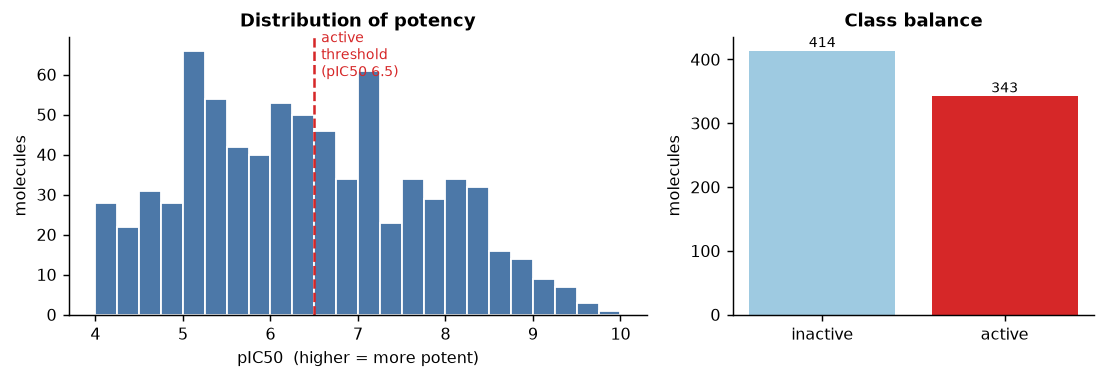

In [4]:
# How potent are these molecules, and how (im)balanced is the active/inactive label?
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8.6, 3.0), gridspec_kw={"width_ratios": [1.6, 1]})
ax1.hist(df.pIC50, bins=24, color="#4c78a8", edgecolor="white")
ax1.axvline(ACTIVE_THR, color="#d62728", ls="--", lw=1.4)
ax1.text(ACTIVE_THR + 0.08, ax1.get_ylim()[1]*0.86, "active\nthreshold\n(pIC50 6.5)", color="#d62728", fontsize=7.5)
ax1.set_xlabel("pIC50  (higher = more potent)"); ax1.set_ylabel("molecules")
ax1.set_title("Distribution of potency")
counts = df.active.value_counts().sort_index()
ax2.bar(["inactive", "active"], counts.values, color=["#9ecae1", "#d62728"])
for i, v in enumerate(counts.values): ax2.text(i, v, str(v), ha="center", va="bottom", fontsize=8)
ax2.set_ylabel("molecules"); ax2.set_title("Class balance")
print("class counts:", counts.to_dict())
fig.tight_layout()

<p class="caption"><b>Figure 1.</b> The dataset we will validate on. Left: the spread of potencies (pIC50); the dashed line is the active/inactive threshold we impose at pIC50 = 6.5 (IC50 ≈ 316 nM). Right: the resulting class balance. The classes are reasonably balanced here, which is itself a luxury — real virtual-screening datasets are often 1 % active, and Section 4 explains why that changes which metric you must report. Every number quoted in this notebook is produced by the cell above it; because the data is fetched live, the exact counts may differ slightly from those in the prose, but the conclusions do not.</p>

The dataset is a mixture of chemical series, as promised. Before modelling, it is worth *seeing* that structure. The gallery below draws a few of the molecules; notice how several share an obvious common core — a quinazoline or a related fused ring bearing an anilino group — the hallmark of a congeneric series and the engine of the leakage we are about to measure.

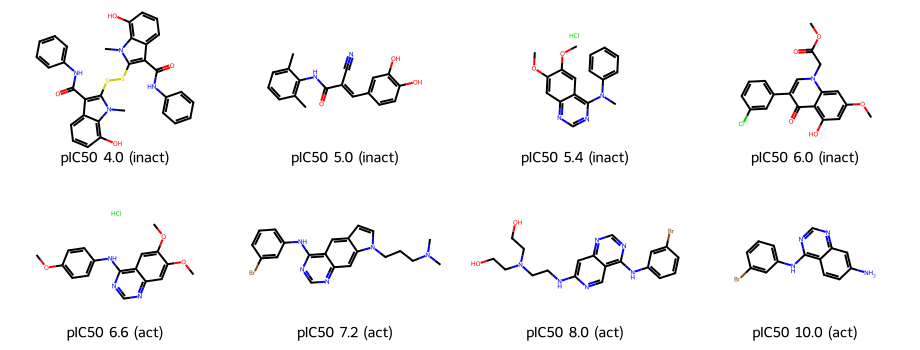

In [5]:
# Draw eight molecules spanning the potency range so the shared cores are visible.
show = df.sort_values("pIC50").iloc[np.linspace(0, len(df)-1, 8).astype(int)]
mols = list(show.mol)
legs = ["pIC50 %.1f (%s)" % (p, "act" if a else "inact")
        for p, a in zip(show.pIC50, show.active)]
Draw.MolsToGridImage(mols, molsPerRow=4, subImgSize=(230, 175), legends=legs)

<p class="caption"><b>Figure 2.</b> Eight EGFR ligands from low to high potency. Many share a fused bicyclic (quinazoline-like) core decorated with an anilino substituent — they are analogs. A random split will put some members of such a group in training and others in the test set, which is exactly the situation that inflates scores. Keep this picture in mind: honest validation is, at bottom, about refusing to let the model see a molecule's twin before it is tested on the molecule itself.</p>

## 3. Featurisation and the baseline model

We turn each molecule — stored as a SMILES string<sup class="c"><a href="#r25">[25]</a></sup> and parsed with RDKit<sup class="c"><a href="#r24">[24]</a></sup> — into a vector and train the random forest of Unit 13. The featurisation is the **Morgan (ECFP-like) fingerprint** of Unit 5: a fixed-length bit vector in which each bit records the presence of a particular circular atom environment.<sup class="c"><a href="#r16">[16]</a></sup> A **random forest** is an ensemble of decision trees, each grown on a bootstrap sample of the data and a random subset of features, whose votes (classification) or averages (regression) are combined;<sup class="c"><a href="#r19">[19]</a></sup> it has been a reliable workhorse for molecular property prediction for twenty years,<sup class="c"><a href="#r4">[4]</a></sup> as has its close relative gradient-boosted trees.<sup class="c"><a href="#r5">[5]</a></sup> None of the validation lessons that follow depend on this choice of model — they apply to any learner, including the deep networks of Unit 15.

In [6]:
# Morgan fingerprints (radius 2, 2048 bits) as a numeric matrix; keep RDKit bit-vectors too.
morgan = AllChem.GetMorganGenerator(radius=2, fpSize=2048)
def to_array(m):
    a = np.zeros((2048,), dtype=np.int8)
    DataStructs.ConvertToNumpyArray(morgan.GetFingerprint(m), a)
    return a
X = np.vstack([to_array(m) for m in df.mol])        # feature matrix  (n_molecules x 2048)
bitvecs = [morgan.GetFingerprint(m) for m in df.mol] # for fast Tanimoto later
y = df.pIC50.values                                  # regression target
yc = df.active.values                                # classification target
print("feature matrix:", X.shape, "| mean bits set per molecule: %.1f" % X.sum(1).mean())

feature matrix: (757, 2048) | mean bits set per molecule: 48.9


## 4. Metrics: reporting the right number

Before we split anything, we must agree on what to measure, because a dishonest metric can hide a dishonest split. We treat the two tasks separately.

For **classification** (active vs inactive) the single most abused metric is accuracy: on a dataset that is 99 % inactive, a model that predicts "inactive" for everything scores 99 % and is useless. Two threshold-free metrics are better.

- **ROC-AUC**, the area under the receiver-operating-characteristic curve, is the probability that a randomly chosen active is ranked above a randomly chosen inactive. It ranges from 0.5 (random) to 1.0 (perfect) and is independent of where you set the decision threshold.
- **PR-AUC** (also called average precision) is the area under the precision–recall curve. Precision is the fraction of predicted actives that are truly active; recall is the fraction of true actives recovered. PR-AUC's baseline is the active fraction itself, so on imbalanced data it exposes failures that ROC-AUC hides — a point argued carefully by Davis & Goadrich<sup class="c"><a href="#r23">[23]</a></sup> and by Saito & Rehmsmeier.<sup class="c"><a href="#r15">[15]</a></sup>

For **regression** (predicting pIC50) we report three complementary numbers:

- **RMSE**, the root-mean-square error, in the units of the target (log-potency units); it is what a chemist feels — "predictions are off by about half a log unit".
- **R²**, the coefficient of determination, the fraction of variance explained; 1.0 is perfect, 0.0 is no better than predicting the mean, and it can go negative on a test set.
- **Spearman's ρ**, the rank correlation; it ignores the exact values and asks only whether the model *orders* molecules correctly — often the real goal, since a project wants to know which compounds to make next, not their precise potency.

Two further distinctions matter in practice. First, a threshold-free metric such as ROC-AUC summarises the *ranking* a model produces, but a deployed classifier must eventually commit to a decision threshold, and the right threshold depends on the cost of a missed active versus a wasted synthesis — a business decision, not a statistical one. Report the ranking metric for model comparison, then choose the operating point separately and report precision and recall there. Second, a model can rank well yet be *miscalibrated*: its predicted probability of 0.9 might correspond to a true hit rate of 0.6. Calibration is a distinct property from discrimination, it is not captured by ROC-AUC or PR-AUC, and it matters whenever the probability itself drives a decision (for example, ranking by expected value). For regression the analogue of calibration is the honesty of the predicted uncertainty, which Section 9 addresses directly. With these caveats noted, we compute all five metrics on a first, ordinary random split, to establish the baseline numbers the rest of the unit will deflate.

In [7]:
# A single 80/20 random split; train both models; compute the five headline metrics.
rng = np.random.RandomState(0)
perm = rng.permutation(len(df)); cut = int(0.8*len(df))
rtr, rte = perm[:cut], perm[cut:]
clf = RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1).fit(X[rtr], yc[rtr])
reg = RandomForestRegressor(n_estimators=300, random_state=0, n_jobs=-1).fit(X[rtr], y[rtr])
proba = clf.predict_proba(X[rte])[:, 1]; yhat = reg.predict(X[rte])
m = dict(ROC_AUC=roc_auc_score(yc[rte], proba), PR_AUC=average_precision_score(yc[rte], proba),
         RMSE=mean_squared_error(y[rte], yhat)**0.5, R2=r2_score(y[rte], yhat),
         Spearman=spearmanr(y[rte], yhat).correlation)
print("RANDOM-SPLIT test metrics (the number too good to be true):")
for k, v in m.items(): print("  %-9s %.3f" % (k, v))

RANDOM-SPLIT test metrics (the number too good to be true):
  ROC_AUC   0.938
  PR_AUC    0.910
  RMSE      0.584
  R2        0.802
  Spearman  0.902


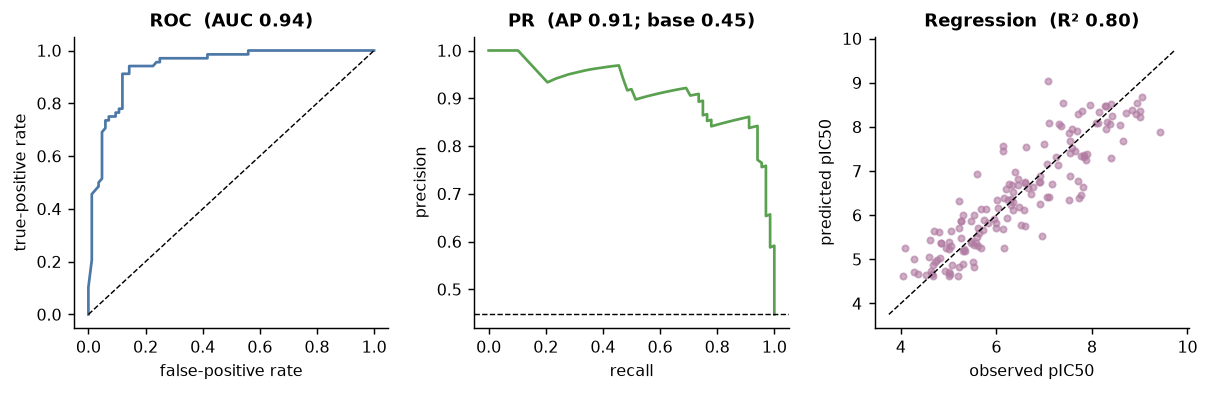

In [8]:
# Visualise the classifier (ROC + PR) and the regressor (predicted vs observed) on the random split.
fig, ax = plt.subplots(1, 3, figsize=(9.4, 3.1))
fpr, tpr, _ = roc_curve(yc[rte], proba)
ax[0].plot(fpr, tpr, color="#4c78a8"); ax[0].plot([0, 1], [0, 1], "k--", lw=0.8)
ax[0].set_xlabel("false-positive rate"); ax[0].set_ylabel("true-positive rate")
ax[0].set_title("ROC  (AUC %.2f)" % m["ROC_AUC"])
prec, rec, _ = precision_recall_curve(yc[rte], proba)
ax[1].plot(rec, prec, color="#59a14f"); ax[1].axhline(yc[rte].mean(), color="k", ls="--", lw=0.8)
ax[1].set_xlabel("recall"); ax[1].set_ylabel("precision")
ax[1].set_title("PR  (AP %.2f; base %.2f)" % (m["PR_AUC"], yc[rte].mean()))
ax[2].scatter(y[rte], yhat, s=12, alpha=0.6, color="#b07aa1")
lims = [y[rte].min()-0.3, y[rte].max()+0.3]; ax[2].plot(lims, lims, "k--", lw=0.8)
ax[2].set_xlabel("observed pIC50"); ax[2].set_ylabel("predicted pIC50")
ax[2].set_title("Regression  (R² %.2f)" % m["R2"])
fig.tight_layout()

<p class="caption"><b>Figure 3.</b> The random-split model looks excellent on every metric: the ROC hugs the top-left corner, the precision–recall curve sits far above its baseline (the dashed line at the active fraction), and the predicted-versus-observed scatter clusters tightly on the diagonal. These are the numbers a careless report would headline. The rest of the unit argues that most of this apparent skill is an artefact of the split, and shows how to measure the part that is real.</p>

<div class="box warn"><h4>Why not accuracy?</h4><p>Accuracy and F1 depend on an arbitrary decision threshold and collapse under class imbalance. ROC-AUC and PR-AUC are threshold-free and rank-based, so they summarise the model across all operating points. On very imbalanced screening data, prefer PR-AUC (and enrichment factors, Unit 9): ROC-AUC can look respectable while the top of the ranked list — the only part a chemist will ever test — is mostly false positives.</p></div>

## 5. Random versus scaffold split

The fix for the leakage of Section 1 is to split so that *whole series stay together*. The most common way to do this is the **scaffold split**: group molecules by their shared core and assign each group entirely to training or entirely to testing, so no scaffold is seen in both. First we must define "core" precisely.

<div class="box bridge"><h4>Chemistry box — the Bemis–Murcko scaffold</h4>
<p>Bemis and Murcko gave an algorithm that reduces a molecule to its <strong>framework</strong>: keep every ring, keep the <em>linker</em> atoms that lie on a path between two rings, and delete everything else — the terminal side chains.<sup class="c"><a href="#r6">[6]</a></sup> What remains is the molecule's skeleton. Aspirin's scaffold is just its benzene ring; two drugs that differ only in substituents hanging off the same rings share a scaffold. It is the computational stand-in for "same series", and it is cheap to compute with RDKit.</p></div>

We will trace the algorithm by hand on one molecule, then confirm it in code — the exercise every unit asks of you.

### 5.1 Worked example by hand: the scaffold of aspirin

Aspirin is <code>CC(=O)Oc1ccccc1C(=O)O</code> — a benzene ring carrying an ester (the acetyl group) and a carboxylic acid. Apply the three rules by hand:

1. **Identify ring atoms.** Only the six aromatic carbons <code>c1ccccc1</code> are in a ring. Keep them.
2. **Identify linker atoms.** A linker is an atom on the shortest path *between two rings*. Aspirin has only one ring, so there are no linkers.
3. **Delete terminal side chains.** Everything not kept in steps 1–2 is a side chain: the whole acetyl ester <code>CC(=O)O–</code> and the whole carboxyl <code>–C(=O)O</code>. Peel them off from their free ends inward until only ring/linker atoms remain.

What survives is the bare benzene ring. So, by hand, **the Murcko scaffold of aspirin is benzene**, <code>c1ccccc1</code>. The cell confirms it and shows two more cases so you can see linkers kept and side chains dropped.

aspirin                              scaffold c1ccccc1               generic C1CCCCC1
diphenylmethane (2 rings + linker)   scaffold c1ccc(Cc2ccccc2)cc1    generic C1CCC(CC2CCCCC2)CC1
an EGFR analog                       scaffold c1ccc(Nc2ncnc3ccccc23)cc1 generic C1CCC(CC2CCCC3CCCCC32)CC1


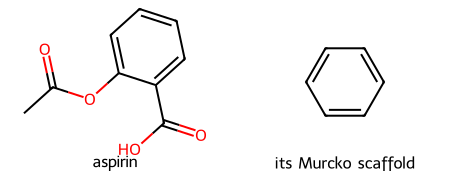

In [9]:
# Confirm the hand trace, and show the generic (atom-type-erased) variant used for coarse grouping.
def murcko_smiles(m):
    return Chem.MolToSmiles(MurckoScaffold.GetScaffoldForMol(m))
def murcko_generic(m):                              # erase atom types & bond orders -> topology only
    return Chem.MolToSmiles(MurckoScaffold.MakeScaffoldGeneric(MurckoScaffold.GetScaffoldForMol(m)))
cases = {"aspirin": "CC(=O)Oc1ccccc1C(=O)O",
         "diphenylmethane (2 rings + linker)": "c1ccccc1Cc1ccccc1",
         "an EGFR analog": df.smiles.iloc[int(np.argmax(df.pIC50))]}
for name, smi in cases.items():
    mm = Chem.MolFromSmiles(smi)
    print("%-36s scaffold %-22s generic %s" % (name, murcko_smiles(mm), murcko_generic(mm)))
asp = Chem.MolFromSmiles(cases["aspirin"])
Draw.MolsToGridImage([asp, MurckoScaffold.GetScaffoldForMol(asp)],
                     molsPerRow=2, subImgSize=(230, 180), legends=["aspirin", "its Murcko scaffold"])

<p class="caption"><b>Figure 4.</b> Aspirin (left) and its Bemis–Murcko scaffold (right): the side chains are gone and the benzene ring remains, exactly as the hand trace predicted. The printout also shows diphenylmethane keeping both rings <em>and</em> the methylene linker between them, and the generic scaffold — which additionally erases atom identities and bond orders, leaving pure topology — used when you want to group by overall shape rather than exact atoms. We group by the ordinary (non-generic) scaffold, the convention of the MoleculeNet benchmark.<sup class="c"><a href="#r2">[2]</a></sup></p>

### 5.2 Building the split and measuring the gap

The scaffold split groups molecules by scaffold and fills the training set with whole groups, largest first, until it holds about 80 % of the data; the remaining groups form the test set. Because the largest, most-populated series land in training, the test set is dominated by scaffolds the model has never seen — precisely the deployment condition. We keep the test-set size identical to the random split so the comparison is fair.

In [10]:
# Group by scaffold; assign whole groups to train (largest first) up to ~80%, rest to test.
from collections import defaultdict
scaffold_of = [murcko_smiles(m) for m in df.mol]
groups = defaultdict(list)
for i, s in enumerate(scaffold_of): groups[s].append(i)
order = sorted(groups.values(), key=len, reverse=True)
s_tr, s_te = [], []
for g in order:
    (s_tr if len(s_tr) < 0.8*len(df) else s_te).extend(g)
s_tr, s_te = np.array(s_tr), np.array(s_te)
n_tr = len(s_tr)
print("distinct scaffolds: %d | singletons: %d | largest series: %d molecules"
      % (len(groups), sum(len(g)==1 for g in groups.values()), max(len(g) for g in groups.values())))
print("scaffold split -> train %d / test %d | test scaffolds unseen in train: %s"
      % (n_tr, len(s_te),
         set(scaffold_of[i] for i in s_te).isdisjoint(set(scaffold_of[i] for i in s_tr))))

distinct scaffolds: 225 | singletons: 137 | largest series: 69 molecules
scaffold split -> train 606 / test 151 | test scaffolds unseen in train: True


In [11]:
# The headline experiment: regression R2 under MANY random splits vs the single scaffold split.
def reg_metrics(tr, te, n_estimators=150):
    mdl = RandomForestRegressor(n_estimators=n_estimators, random_state=0, n_jobs=-1).fit(X[tr], y[tr])
    p = mdl.predict(X[te])
    return r2_score(y[te], p), mean_squared_error(y[te], p)**0.5, spearmanr(y[te], p).correlation
rand_r2 = []
for seed in range(20):
    pm = np.random.RandomState(seed).permutation(len(df))
    rand_r2.append(reg_metrics(pm[:n_tr], pm[n_tr:])[0])
scaf_r2, scaf_rmse, scaf_rho = reg_metrics(s_tr, s_te)
print("random-split  R2: mean %.3f  (min %.3f, max %.3f over 20 seeds)"
      % (np.mean(rand_r2), np.min(rand_r2), np.max(rand_r2)))
print("scaffold-split R2: %.3f   RMSE %.3f   Spearman %.3f" % (scaf_r2, scaf_rmse, scaf_rho))
print("optimism of the random split: Delta-R2 = %.3f" % (np.mean(rand_r2) - scaf_r2))

random-split  R2: mean 0.768  (min 0.690, max 0.825 over 20 seeds)
scaffold-split R2: 0.664   RMSE 0.767   Spearman 0.814
optimism of the random split: Delta-R2 = 0.104


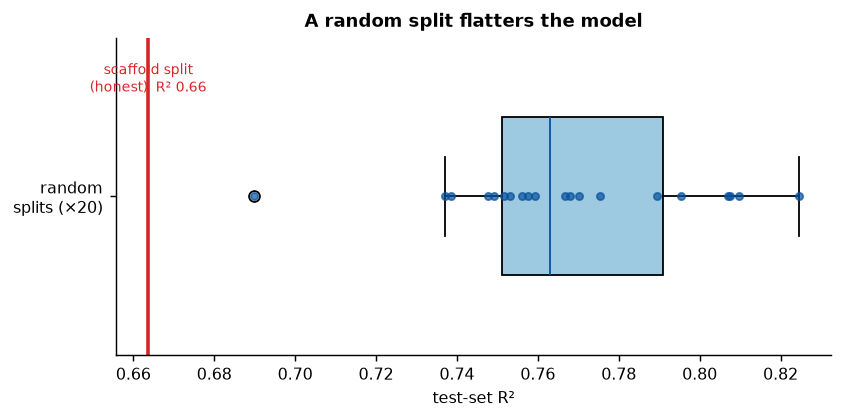

In [12]:
# Visualise the optimism: the random-split R2 distribution vs the honest scaffold-split value.
fig, ax = plt.subplots(figsize=(6.6, 3.3))
ax.boxplot([rand_r2], orientation="horizontal", widths=0.5, patch_artist=True,
           boxprops=dict(facecolor="#9ecae1"), medianprops=dict(color="#08519c"))
ax.scatter(rand_r2, np.ones(len(rand_r2)), color="#08519c", s=16, zorder=3, alpha=0.7)
ax.axvline(scaf_r2, color="#d62728", lw=2)
ax.text(scaf_r2, 1.33, "scaffold split\n(honest)  R² %.2f" % scaf_r2, color="#d62728", fontsize=8, ha="center")
ax.set_yticks([1]); ax.set_yticklabels(["random\nsplits (×20)"])
ax.set_xlabel("test-set R²"); ax.set_title("A random split flatters the model")
fig.tight_layout()

<p class="caption"><b>Figure 5.</b> Twenty random 80/20 splits (blue) all report a high R², tightly clustered — reshuffling the rows does not help you discover that anything is wrong. The honest scaffold split (red line) sits well below the entire random-split cloud. The difference — here around a tenth of R², with a matching widening of RMSE — is the <em>optimism</em> of the random split: it is the portion of the headline score that comes from testing on molecules whose relatives were in training. Sheridan reported exactly this pattern across many industrial datasets and argued that a split simulating prospective use is the only trustworthy estimate of future performance.<sup class="c"><a href="#r1">[1]</a></sup></p>

<div class="box bridge"><h4>Chemistry box — time splits, the industrial gold standard</h4>
<p>Scaffold splitting is a proxy for the real thing: a <strong>time split</strong> trains on compounds measured before a cut-off date and tests on those measured after, reproducing how a model is actually used — fit on today's project, applied to tomorrow's molecules.<sup class="c"><a href="#r1">[1]</a></sup> It is the most realistic protocol when timestamps are available (ChEMBL records a document year), and controlled studies confirm that how you choose the training and test sets materially changes the apparent outcome of QSAR modelling.<sup class="c"><a href="#r13">[13]</a></sup> We use scaffold splitting here because it needs no dates and isolates the chemical-novelty effect cleanly, but when you can time-split, do.</p></div>

## 6. Analog and cluster leakage, made visible

Section 5 showed the *consequence* of leakage; this section shows the *mechanism*. The claim is that a random split flatters the model because its test molecules sit close to training molecules in chemical space. We can measure that closeness directly with the **Tanimoto similarity** of Unit 5: for two fingerprints it is the number of bits they share divided by the number set in either, a value in [0, 1] where 1 means identical bit patterns.<sup class="c"><a href="#r16">[16]</a></sup> For each test molecule we find its single nearest training neighbour and record that similarity. If random splitting leaks, its test molecules should have systematically closer neighbours than the scaffold split's.

median NN similarity -- random: 0.761 | scaffold: 0.688


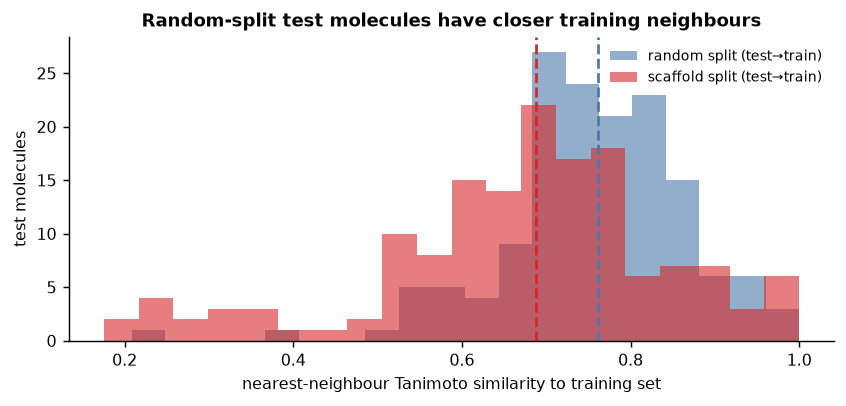

In [13]:
# Nearest-neighbour Tanimoto from each test molecule to the training set, under both splits.
def nn_similarity(test_idx, train_idx):
    tb = [bitvecs[j] for j in train_idx]
    return np.array([max(DataStructs.BulkTanimotoSimilarity(bitvecs[i], tb)) for i in test_idx])
rng = np.random.RandomState(0); pm = rng.permutation(len(df))
nn_rand = nn_similarity(pm[n_tr:], pm[:n_tr])
nn_scaf = nn_similarity(s_te, s_tr)
fig, ax = plt.subplots(figsize=(6.6, 3.2))
ax.hist(nn_rand, bins=20, alpha=0.6, color="#4c78a8", label="random split (test→train)")
ax.hist(nn_scaf, bins=20, alpha=0.6, color="#d62728", label="scaffold split (test→train)")
ax.axvline(np.median(nn_rand), color="#4c78a8", ls="--"); ax.axvline(np.median(nn_scaf), color="#d62728", ls="--")
ax.set_xlabel("nearest-neighbour Tanimoto similarity to training set"); ax.set_ylabel("test molecules")
ax.set_title("Random-split test molecules have closer training neighbours"); ax.legend(fontsize=7.5, frameon=False)
print("median NN similarity -- random: %.3f | scaffold: %.3f" % (np.median(nn_rand), np.median(nn_scaf)))
fig.tight_layout()

<p class="caption"><b>Figure 6.</b> The distance each test molecule sits from the nearest training molecule, measured by Tanimoto similarity. Under the random split (blue) the distribution is shifted toward 1.0 — many test molecules have a very close training analog. The scaffold split (red) pushes mass toward lower similarity: its test molecules are genuinely more novel. This shift is the leakage of Section 1 made quantitative, and it is the lever behind the inflated random-split score.</p>

Leakage matters only if closeness actually buys accuracy. It does: a model predicts a molecule well precisely when a similar molecule was in training — Sheridan showed that similarity-to-training-set is itself a good predictor of per-compound reliability.<sup class="c"><a href="#r14">[14]</a></sup> We verify it on our scaffold-split test molecules.

mean |error| by similarity bin: {'0.0-0.3': 0.83, '0.3-0.5': 1.067, '0.5-0.7': 0.543, '0.7-1.0': 0.517}
Spearman(similarity, -error) = 0.186


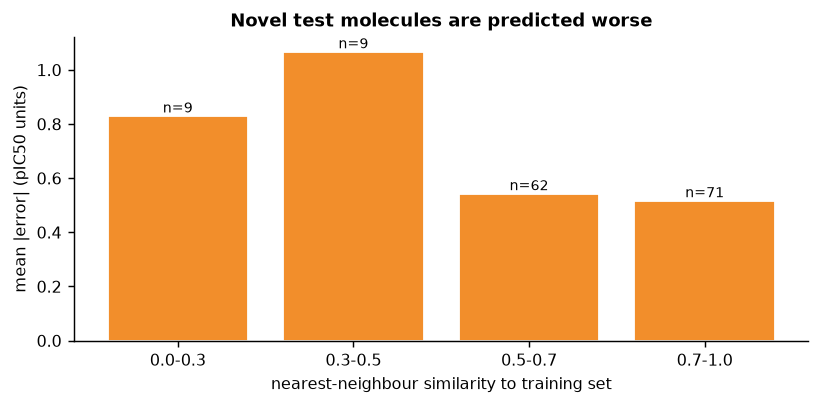

In [14]:
# Does prediction error grow as a test molecule's nearest training neighbour gets more distant?
mdl = RandomForestRegressor(n_estimators=300, random_state=0, n_jobs=-1).fit(X[s_tr], y[s_tr])
abserr = np.abs(y[s_te] - mdl.predict(X[s_te]))
bins = pd.cut(nn_scaf, [0, 0.3, 0.5, 0.7, 1.01], labels=["0.0-0.3", "0.3-0.5", "0.5-0.7", "0.7-1.0"])
tab = (pd.DataFrame({"sim_bin": bins, "abs_err": abserr})
         .groupby("sim_bin", observed=True)["abs_err"].agg(["size", "mean"]).round(3))
fig, ax = plt.subplots(figsize=(6.4, 3.2))
ax.bar(tab.index.astype(str), tab["mean"], color="#f28e2b", edgecolor="white")
for i, (n, mu) in enumerate(zip(tab["size"], tab["mean"])): ax.text(i, mu, "n=%d" % n, ha="center", va="bottom", fontsize=8)
ax.set_xlabel("nearest-neighbour similarity to training set"); ax.set_ylabel("mean |error| (pIC50 units)")
ax.set_title("Novel test molecules are predicted worse")
print("mean |error| by similarity bin:", {k: round(v, 3) for k, v in tab["mean"].items()})
print("Spearman(similarity, -error) = %.3f" % spearmanr(nn_scaf, -abserr).correlation)
fig.tight_layout()

<p class="caption"><b>Figure 7.</b> Mean absolute prediction error on the scaffold-split test set, binned by how similar each molecule is to its nearest training neighbour. Molecules with a close analog in training (right-hand bars) are predicted more accurately than molecules with no close analog (left-hand bars): the mean absolute error rises from about 0.5 log units for the most similar molecules to roughly 0.8–1.1 for the least similar, as the printed per-bin values show. The positive rank correlation between similarity and (negative) error, also printed above, says the same thing continuously. This is why packing the test set with close analogs — what a random split does — manufactures accuracy: it fills the test set with the easy right-hand bars.</p>

### 6.1 A deliberate leakage experiment

To nail the point, we engineer leakage and watch the score inflate. Take the single largest analog series (one scaffold, many members) and compare two protocols on exactly the same molecules: (a) *hold the series out* — train on everything else, test on the whole series (honest: the series is new chemistry); (b) *split the series* — put half its members in training and test on the other half (leaky: every test molecule has a near-twin in training).

In [15]:
# One analog series, two protocols: hold it out (honest) vs split it across train/test (leaky).
big = max(groups.values(), key=len)                 # indices of the most populated scaffold
rest = np.array([i for i in range(len(df)) if i not in set(big)])
# (a) honest: train on all other scaffolds, test on the whole series
r2_holdout = r2_score(y[big],
    RandomForestRegressor(n_estimators=300, random_state=0, n_jobs=-1).fit(X[rest], y[rest]).predict(X[big]))
# (b) leaky: half the series in training, test on the other half
big = np.array(big); hp = np.random.RandomState(0).permutation(len(big)); h = len(big)//2
tr_leaky = np.concatenate([rest, big[hp[:h]]]); te_leaky = big[hp[h:]]
r2_leaky = r2_score(y[te_leaky],
    RandomForestRegressor(n_estimators=300, random_state=0, n_jobs=-1).fit(X[tr_leaky], y[tr_leaky]).predict(X[te_leaky]))
print("largest series: %d molecules, scaffold %s" % (len(big), scaffold_of[big[0]]))
print("(a) hold series out  -> R2 = %.3f   (honest: this chemotype is new)" % r2_holdout)
print("(b) split the series -> R2 = %.3f   (leaky: twins are in training)" % r2_leaky)

largest series: 69 molecules, scaffold c1ccc(Nc2ncnc3ccccc23)cc1
(a) hold series out  -> R2 = 0.515   (honest: this chemotype is new)
(b) split the series -> R2 = 0.678   (leaky: twins are in training)


The two numbers are computed on molecules drawn from *the same chemical series*, yet the leaky protocol reports a clearly higher R² than the honest one. Nothing about the chemistry changed; only whether the model was allowed to see near-twins of the test molecules. This is the whole disease in one experiment — and it is why benchmark results that quietly use random splits can be, as Wallach & Heifets put it, mostly a measurement of memorisation.<sup class="c"><a href="#r21">[21]</a></sup><sup class="c"><a href="#r22">[22]</a></sup>

<div class="box bridge"><h4>Chemistry box — cluster leakage and why clustering helps</h4>
<p>Scaffolds are one way to find series, but two molecules can be near-duplicates without sharing an exact Murcko scaffold (a ring swapped for a similar ring). A more general defence is to <strong>cluster</strong> the molecules by fingerprint similarity — the Butina algorithm groups everything within a similarity radius<sup class="c"><a href="#r17">[17]</a></sup> — and then split whole clusters. Cluster splitting catches analog leakage that scaffold splitting misses; it is the logic behind debiasing schemes such as asymmetric validation embedding.<sup class="c"><a href="#r21">[21]</a></sup></p></div>

## 7. The applicability domain

Figure 7 taught the operational lesson: a model is trustworthy near its training data and unreliable far from it. The region of chemical space where a model's predictions can be trusted is its **applicability domain (AD)**, and defining it is a formal requirement of validated QSAR under the OECD principles.<sup class="c"><a href="#r9">[9]</a></sup><sup class="c"><a href="#r27">[27]</a></sup> An AD lets a model say "I don't know" instead of extrapolating confidently into chemistry it has never seen — the single most valuable thing an honest model can do in production. There are many AD definitions;<sup class="c"><a href="#r10">[10]</a></sup> we build the two most common.

### 7.1 Distance-to-model

The simplest AD declares a test molecule *in domain* if it is close enough to the training set. We already have the measure: nearest-neighbour Tanimoto similarity (Figure 6). Pick a threshold — a common choice is around 0.3–0.4 — and flag anything below it as out-of-domain. We then check that errors are indeed larger outside the domain, which is the only thing that makes an AD worth having.

In [16]:
# Distance-to-model AD: flag test molecules whose nearest-training similarity is below a threshold.
AD_SIM = 0.35
in_dom = nn_scaf >= AD_SIM
rmse = lambda e: np.sqrt(np.mean(e**2))
print("scaffold-split test molecules: %d in-domain, %d out-of-domain (sim < %.2f)"
      % (in_dom.sum(), (~in_dom).sum(), AD_SIM))
print("RMSE in-domain : %.3f" % rmse(abserr[in_dom]))
print("RMSE out-domain: %.3f" % rmse(abserr[~in_dom]))
print("coverage (fraction kept): %.2f" % in_dom.mean())

scaffold-split test molecules: 140 in-domain, 11 out-of-domain (sim < 0.35)
RMSE in-domain : 0.748
RMSE out-domain: 1.008
coverage (fraction kept): 0.93


Restricting predictions to the applicability domain trades **coverage** for **accuracy**: you answer fewer questions but the answers you give are better. A deployed model reports its in-domain predictions and abstains on the rest, which is exactly how a chemist wants to use it. The choice of threshold is itself a dial on this trade-off, and the honest way to present it is a curve: sweep the similarity threshold from permissive to strict and plot the resulting error against the fraction of molecules retained. A good model shows a steadily falling error as coverage shrinks — evidence that the AD is ranking reliability correctly — whereas a flat curve means the similarity measure is not telling you anything about where the model can be trusted. The threshold you finally pick depends on the project: an early screen tolerates low precision for high coverage, while a go/no-go decision on a single expensive synthesis demands the strict end of the curve. The second AD definition comes from classical statistics and does not need fingerprints at all.

### 7.2 Leverage and the Williams plot

In linear modelling, a point's **leverage** measures how unusual its descriptors are relative to the training set. For a descriptor matrix $X$ (with an intercept column) the *hat matrix* is $H = X(X^\top X)^{-1}X^\top$, and the leverage of molecule $i$ is its diagonal element $h_i = x_i^\top (X^\top X)^{-1} x_i$. High leverage means "far from the centre of the training cloud". The conventional warning threshold is $h^* = 3p/n$, where $p$ is the number of descriptors (plus intercept) and $n$ the training-set size.<sup class="c"><a href="#r8">[8]</a></sup><sup class="c"><a href="#r27">[27]</a></sup> A **Williams plot** of standardised residual against leverage then shows two kinds of trouble at once: points to the right of $h^*$ are structurally outside the domain; points above/below ±3 standardised-residual units are response outliers. We compute leverage on a small, interpretable set of physicochemical descriptors.

In [17]:
# Leverage on 8 physicochemical descriptors; standardise using TRAINING statistics only.
def descvec(m):
    return [Descriptors.MolWt(m), Crippen.MolLogP(m), Descriptors.TPSA(m), Lipinski.NumHDonors(m),
            Lipinski.NumHAcceptors(m), Descriptors.NumRotatableBonds(m),
            rdMolDescriptors.CalcNumAromaticRings(m), Descriptors.FractionCSP3(m)]
D = np.array([descvec(m) for m in df.mol], float)
mu, sd = D[s_tr].mean(0), D[s_tr].std(0)
Dz = np.hstack([np.ones((len(D), 1)), (D - mu)/sd])        # add intercept column
XtXinv = np.linalg.inv(Dz[s_tr].T @ Dz[s_tr])
lev = np.einsum("ij,jk,ik->i", Dz, XtXinv, Dz)            # h_i for every molecule
p = Dz.shape[1]; h_star = 3*p/len(s_tr)
resid = (y[s_te] - mdl.predict(X[s_te])); std_resid = resid/resid.std()
print("h* = %.3f | test molecules with leverage > h*: %d of %d"
      % (h_star, int((lev[s_te] > h_star).sum()), len(s_te)))
print("RMSE within leverage: %.3f | RMSE beyond leverage: %.3f"
      % (rmse(abserr[lev[s_te] <= h_star]), rmse(abserr[lev[s_te] > h_star]) if (lev[s_te] > h_star).any() else float('nan')))

h* = 0.045 | test molecules with leverage > h*: 5 of 151
RMSE within leverage: 0.767 | RMSE beyond leverage: 0.851


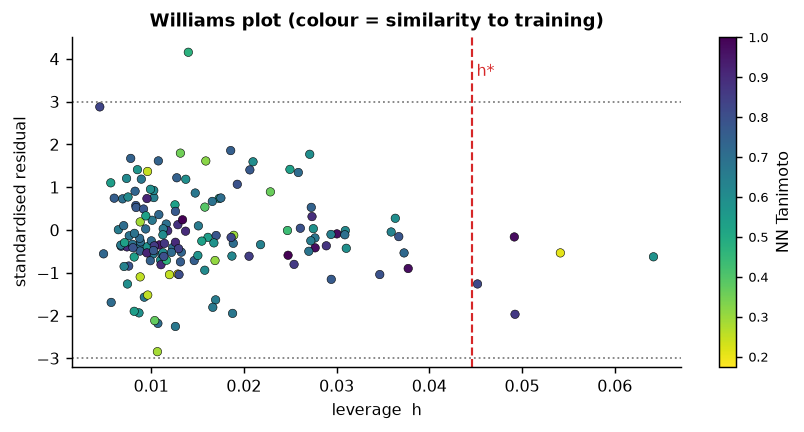

In [18]:
# The Williams plot: standardised residual vs leverage for the scaffold-split test set.
fig, ax = plt.subplots(figsize=(6.6, 3.4))
sc = ax.scatter(lev[s_te], std_resid, c=nn_scaf, cmap="viridis_r", s=22, edgecolor="k", linewidth=0.3)
ax.axvline(h_star, color="#d62728", ls="--", lw=1.2); ax.text(h_star, ax.get_ylim()[1]*0.8, " h*", color="#d62728")
for yv in (-3, 3): ax.axhline(yv, color="gray", ls=":", lw=1)
ax.set_xlabel("leverage  h"); ax.set_ylabel("standardised residual")
ax.set_title("Williams plot (colour = similarity to training)")
fig.colorbar(sc, ax=ax, label="NN Tanimoto").ax.tick_params(labelsize=7)
fig.tight_layout()

<p class="caption"><b>Figure 8.</b> The Williams plot of the scaffold-split test set. The vertical dashed line is the leverage threshold h* = 3p/n; molecules to its right are structurally unusual relative to training. The horizontal dotted lines at ±3 bound the acceptable standardised residuals; points beyond them are response outliers. Colour encodes nearest-neighbour similarity, tying this descriptor-space view back to the fingerprint-space view of Section 6: the two applicability-domain definitions — leverage and distance-to-model — flag overlapping but not identical molecules, which is why practitioners often combine them.<sup class="c"><a href="#r10">[10]</a></sup> Either way, molecules outside the domain carry larger errors, as the printed RMSE comparison confirms.</p>

<div class="box warn"><h4>An AD is necessary, not sufficient</h4><p>Being inside the applicability domain means a prediction is <em>plausible</em>, not <em>correct</em>. The AD controls extrapolation; it cannot rescue a model whose training labels are noisy or whose featurisation misses the relevant chemistry. Report AD coverage alongside metrics so a reader knows what fraction of test space the headline number actually covers.</p></div>

## 8. y-randomisation: is the score real at all?

Even an honest split can mislead if the dataset is small or the features numerous: a model may stumble onto a chance correlation between structure and activity. **y-randomisation** (also called a permutation test, or Y-scrambling) is the cheap, decisive check.<sup class="c"><a href="#r11">[11]</a></sup> Shuffle the labels so that every molecule keeps its features but gets a random activity, retrain, and measure test performance. Repeat many times to build a **null distribution** of "scores achievable by luck". A genuine model scores far above this null; a model whose real score falls inside the null has learned nothing but noise. Golbraikh and Tropsha argued in their classic "Beware of q²!" that a high internal fit statistic is no guarantee of predictivity, and that permutation and external tests like this one are essential.<sup class="c"><a href="#r7">[7]</a></sup> This mirrors the hypothesis-testing logic from your statistics course: the null is "features and labels are unrelated", and the real score is the test statistic.

In [19]:
# Shuffle the training labels, retrain, score on the (unshuffled) test set; repeat to form a null.
def train_score(ytrain, tr=s_tr, te=s_te, n_estimators=120):
    return r2_score(y[te],
        RandomForestRegressor(n_estimators=n_estimators, random_state=0, n_jobs=-1).fit(X[tr], ytrain).predict(X[te]))
real_r2 = train_score(y[s_tr])
null_r2 = [train_score(np.random.RandomState(k).permutation(y[s_tr])) for k in range(30)]
p_value = (1 + sum(n >= real_r2 for n in null_r2)) / (1 + len(null_r2))
print("real scaffold-split R2 : %.3f" % real_r2)
print("y-randomised null R2   : mean %.3f, max %.3f (30 permutations)" % (np.mean(null_r2), np.max(null_r2)))
print("permutation p-value    : %.3f" % p_value)

real scaffold-split R2 : 0.661
y-randomised null R2   : mean -0.137, max 0.068 (30 permutations)
permutation p-value    : 0.032


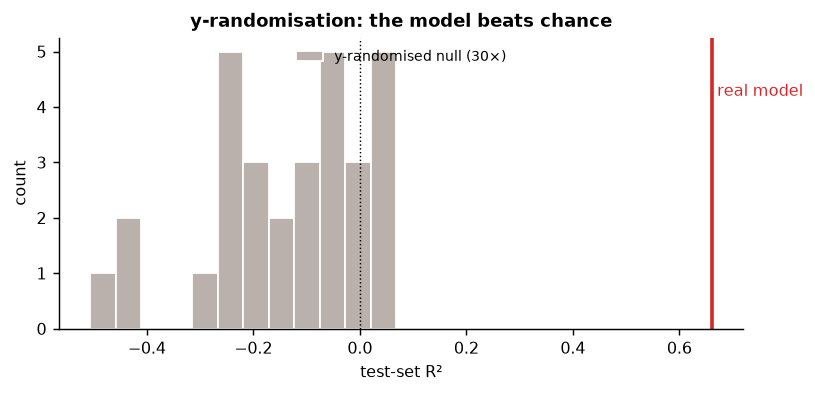

In [20]:
# The real score sits far above the y-randomised null.
fig, ax = plt.subplots(figsize=(6.4, 3.1))
ax.hist(null_r2, bins=12, color="#bab0ac", edgecolor="white", label="y-randomised null (30×)")
ax.axvline(real_r2, color="#d62728", lw=2); ax.text(real_r2, ax.get_ylim()[1]*0.8, " real model", color="#d62728")
ax.axvline(0, color="k", lw=0.8, ls=":")
ax.set_xlabel("test-set R²"); ax.set_ylabel("count"); ax.set_title("y-randomisation: the model beats chance")
ax.legend(fontsize=7.5, frameon=False, loc="upper center")
fig.tight_layout()

<p class="caption"><b>Figure 9.</b> The null distribution of test R² obtained by scrambling the training labels (grey) clusters around zero — indeed slightly negative, because a model fitted to noise does worse than predicting the mean — while the real model (red) sits far to the right. The permutation p-value sits at its floor for thirty permutations (about 0.03 — no scrambled run came anywhere near the real score): the structure-activity relationship the model found is not a fluke of this dataset, and more permutations would only drive the estimate lower. Had the real score landed inside the grey cloud, the "model" would have been an elaborate way of fitting noise, regardless of how good the split or the metric looked.</p>

## 9. Uncertainty: how much to trust each prediction

A single predicted number is half an answer; a chemist deciding whether to synthesise a compound needs to know how sure the model is. Two lightweight techniques give per-prediction uncertainty without any deep-learning machinery.

The first is almost free with an ensemble. A random forest is a committee of trees; the **spread of their individual predictions** is a natural confidence measure — wide disagreement means "unsure". The second is **conformal prediction**, a distribution-free framework that converts any model into one that outputs calibrated intervals with a guaranteed coverage rate.<sup class="c"><a href="#r12">[12]</a></sup> In its simplest *split-conformal* form: hold out a calibration set, record the model's absolute errors on it, and take the (1−α) quantile of those errors as a fixed half-width; the resulting interval [prediction ± half-width] is guaranteed to contain the truth about (1−α) of the time on exchangeable data, with no assumption about the error distribution. The two approaches answer subtly different questions. The ensemble spread is a *heuristic*: it is cheap, it correlates with error, and it is excellent for ranking which predictions to distrust, but the number itself has no guaranteed meaning — a spread of 0.5 does not promise any particular error rate. Conformal prediction is a *guarantee*: in exchange for a held-out calibration set and the mild assumption of exchangeability, it delivers intervals whose long-run coverage is provably (1−α), whatever the underlying model or error distribution. The price is that the simplest conformal interval has a fixed width for every molecule, which is pessimistic for easy predictions and optimistic for hard ones; more elaborate variants make the width adapt to local difficulty, often by scaling it with exactly the kind of ensemble spread we compute here. In production you usually want both: the conformal interval to state a defensible confidence level, and the ensemble spread (or the applicability domain) to flag which molecules sit at the difficult end. We build both and check that the conformal intervals actually achieve their promised 90 % coverage.

In [21]:
# Split-conformal 90% intervals: fit on part of train, calibrate on the rest, test on scaffold test set.
cut2 = int(0.75*len(s_tr)); fit_idx, cal_idx = s_tr[:cut2], s_tr[cut2:]
cmodel = RandomForestRegressor(n_estimators=300, random_state=0, n_jobs=-1).fit(X[fit_idx], y[fit_idx])
cal_err = np.abs(y[cal_idx] - cmodel.predict(X[cal_idx]))
alpha = 0.10
q = np.quantile(cal_err, np.ceil((len(cal_idx)+1)*(1-alpha))/len(cal_idx))  # finite-sample conformal quantile
pred = cmodel.predict(X[s_te])
covered = np.abs(y[s_te] - pred) <= q
# ensemble spread as an informal uncertainty, for comparison
per_tree = np.stack([t.predict(X[s_te]) for t in cmodel.estimators_])
ens_std = per_tree.std(0)
print("conformal 90%% interval half-width: %.2f pIC50 units" % q)
print("empirical coverage on test set    : %.2f  (target 0.90)" % covered.mean())
print("ensemble-std vs |error| rank corr : %.2f" % spearmanr(ens_std, np.abs(y[s_te]-pred)).correlation)

conformal 90% interval half-width: 1.55 pIC50 units
empirical coverage on test set    : 0.92  (target 0.90)
ensemble-std vs |error| rank corr : 0.28


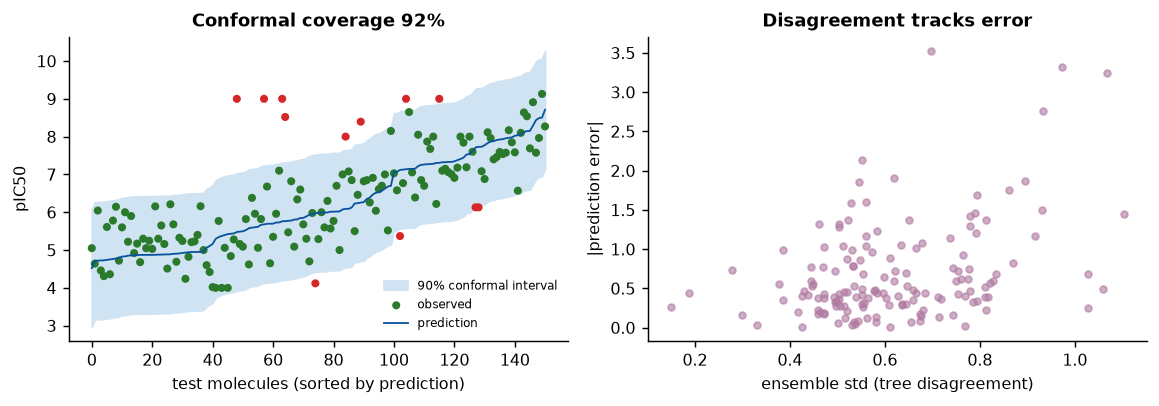

In [22]:
# Left: do conformal intervals cover the truth? Right: does ensemble disagreement track error?
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.0, 3.2))
o = np.argsort(pred); xs = np.arange(len(pred))
a1.fill_between(xs, pred[o]-q, pred[o]+q, color="#cfe3f3", label="90% conformal interval")
a1.scatter(xs, y[s_te][o], s=12, color=np.where(covered[o], "#2b7a2b", "#d62728"), label="observed")
a1.plot(xs, pred[o], color="#08519c", lw=1, label="prediction")
a1.set_xlabel("test molecules (sorted by prediction)"); a1.set_ylabel("pIC50")
a1.set_title("Conformal coverage %.0f%%" % (100*covered.mean())); a1.legend(fontsize=6.5, frameon=False)
a2.scatter(ens_std, np.abs(y[s_te]-pred), s=14, alpha=0.6, color="#b07aa1")
a2.set_xlabel("ensemble std (tree disagreement)"); a2.set_ylabel("|prediction error|")
a2.set_title("Disagreement tracks error")
fig.tight_layout()

<p class="caption"><b>Figure 10.</b> Left: each test molecule with its 90 % conformal interval (band); green points fall inside, red outside, and the empirical coverage matches the promised 90 % — the guarantee holds despite us making no assumption about the shape of the errors. Right: the random forest's internal disagreement (the standard deviation across its trees) rises with the actual error, so even the free ensemble spread is a usable, if uncalibrated, confidence signal. Uncertainty and the applicability domain are two views of the same humility: both let the model flag the predictions a project should not bet on.</p>

## 10. Community benchmarks: MoleculeNet and the Therapeutics Data Commons

You do not have to assemble a validation protocol from scratch for every project; the community maintains curated benchmark suites that bundle datasets with recommended splits and metrics, so that published models can be compared honestly.

- **MoleculeNet** collects classification and regression datasets across quantum, physical-chemistry, biophysics and physiology tasks, and — crucially for this unit — ships a **scaffold splitter** as the default for most sets, precisely to discourage the inflated random-split scores we have been dissecting.<sup class="c"><a href="#r2">[2]</a></sup> It standardises which metric to report per task (ROC-AUC for imbalanced classification, RMSE or MAE for regression).
- The **Therapeutics Data Commons (TDC)** is a broader, actively maintained platform spanning the whole drug-development pipeline — ADMET, target interaction, high-throughput screening, generation — with programmatic access and, again, built-in scaffold and cold-start splits plus leaderboards.<sup class="c"><a href="#r3">[3]</a></sup> It is the natural place to find a well-posed task and a fair baseline.

Using these benchmarks does not absolve you of judgement: a leaderboard number earned under a scaffold split can still hide label noise or an undefined applicability domain. But adopting their splits and metrics means your results are comparable and your evaluation starts from a defensible protocol rather than the seductive random split. The table summarises a few representative tasks and the split each benchmark recommends.

In [23]:
# A compact map of common benchmark tasks and the evaluation protocol each recommends.
bench = pd.DataFrame([
    ("MoleculeNet", "BBBP",      "classification", "blood-brain barrier penetration", "scaffold", "ROC-AUC"),
    ("MoleculeNet", "BACE",      "classification", "beta-secretase inhibition",       "scaffold", "ROC-AUC"),
    ("MoleculeNet", "Tox21",     "classification", "12 toxicity assays (imbalanced)",  "random/scaffold", "ROC-AUC"),
    ("MoleculeNet", "ESOL",      "regression",     "aqueous solubility",               "random/scaffold", "RMSE"),
    ("MoleculeNet", "FreeSolv",  "regression",     "hydration free energy",            "scaffold", "RMSE"),
    ("TDC",         "Caco2_Wang","regression",     "intestinal permeability",          "scaffold", "MAE"),
    ("TDC",         "hERG",      "classification", "cardiotoxicity channel block",     "scaffold", "ROC-AUC"),
    ("TDC",         "LD50_Zhu",  "regression",     "acute oral toxicity",              "scaffold", "MAE"),
], columns=["suite", "dataset", "task", "endpoint", "recommended split", "primary metric"])
print(bench.to_string(index=False))

      suite    dataset           task                        endpoint recommended split primary metric
MoleculeNet       BBBP classification blood-brain barrier penetration          scaffold        ROC-AUC
MoleculeNet       BACE classification       beta-secretase inhibition          scaffold        ROC-AUC
MoleculeNet      Tox21 classification 12 toxicity assays (imbalanced)   random/scaffold        ROC-AUC
MoleculeNet       ESOL     regression              aqueous solubility   random/scaffold           RMSE
MoleculeNet   FreeSolv     regression           hydration free energy          scaffold           RMSE
        TDC Caco2_Wang     regression         intestinal permeability          scaffold            MAE
        TDC       hERG classification    cardiotoxicity channel block          scaffold        ROC-AUC
        TDC   LD50_Zhu     regression             acute oral toxicity          scaffold            MAE


<p class="caption"><b>Table.</b> A representative slice of the MoleculeNet<sup class="c"><a href="#r2">[2]</a></sup> and TDC<sup class="c"><a href="#r3">[3]</a></sup> benchmarks. Note how often the recommended split is "scaffold" rather than "random" — the benchmark designers have internalised the lesson of this unit. When you report on a new dataset of your own, imitate this discipline: state the split, state the metric, define the applicability domain, and run a y-randomisation check. The Lenselink et al. temporal benchmark on ChEMBL is a good template for doing this rigorously on real bioactivity data.<sup class="c"><a href="#r20">[20]</a></sup></p>

## 11. Summary

You should now be able to explain, without notes:

- The deployment question — accuracy on *new chemistry* — and why a random split answers a different, easier question.
- Why bioactivity datasets are built of analog series, and how that group structure causes leakage through chemical similarity.
- How to build a Bemis–Murcko scaffold split, and how to quantify the random-vs-scaffold optimism gap on a real dataset.
- How to make leakage visible with nearest-neighbour Tanimoto similarity, and how to demonstrate it by splitting versus holding out a single analog series.
- Two applicability-domain definitions — distance-to-model and leverage (the hat matrix, with threshold h* = 3p/n and the Williams plot) — and that errors grow outside the domain.
- The y-randomisation null and how it certifies that a score is better than chance.
- The right metrics for each task: ROC-AUC and PR-AUC (and why PR-AUC matters under imbalance); RMSE, R² and Spearman's ρ for regression.
- How to attach uncertainty to predictions with an ensemble's spread and with split conformal prediction, and what a coverage guarantee means.
- What MoleculeNet and the Therapeutics Data Commons provide and why their default splits are scaffold-based.

<div class="box key"><h4>The honest-validation checklist</h4>
<p>Before you believe a molecular model: (1) split by scaffold, cluster or time, never at random; (2) report ROC-AUC <em>and</em> PR-AUC, or RMSE, R² <em>and</em> Spearman — never accuracy alone; (3) define and report an applicability domain with its coverage; (4) run y-randomisation; (5) attach per-prediction uncertainty; (6) say which of these you did. A model that survives all six is worth acting on.</p></div>

## 12. Self-assessment

<details><summary>Q1. In one sentence, what question does a random train/test split fail to answer for a molecular model?</summary>Whether the model works on <em>new chemistry</em> — chemotypes unlike anything in training — because a random split fills the test set with close analogs of training molecules, measuring interpolation within known series rather than generalisation to novel ones.</details>

<details><summary>Q2. Define the Bemis–Murcko scaffold and give aspirin's.</summary>Keep all rings and the linker atoms on paths between rings, delete all terminal side chains. Aspirin (benzene bearing an ester and an acid) reduces to its benzene ring, <code>c1ccccc1</code>.</details>

<details><summary>Q3. A dataset is 2 % active. A model has ROC-AUC 0.90 but PR-AUC 0.25. What does that tell you, and which metric should you headline?</summary>ROC-AUC looks great but is forgiving under heavy imbalance; the low PR-AUC (baseline 0.02, so 0.25 is above chance but modest) reveals that the top of the ranked list is mostly false positives. Headline PR-AUC (and enrichment), because that is what a chemist testing the top hits will experience.</details>

<details><summary>Q4. You observe test R² = 0.80 under a random split and 0.55 under a scaffold split, same dataset. What is the 0.25 gap called and what causes it?</summary>It is the optimism (leakage) of the random split. It is caused by test molecules having close training analogs under random splitting; the scaffold split removes those analogs, giving the honest estimate of performance on new scaffolds.</details>

<details><summary>Q5. How would you demonstrate analog leakage with a single analog series?</summary>Compare two protocols on the same series: hold the whole series out (train on everything else) versus split the series across train and test. The second reports a much higher score although the molecules are identical — the only difference is whether near-twins were visible in training.</details>

<details><summary>Q6. Define the applicability domain and give two ways to compute it.</summary>The region of chemical space where the model's predictions are trustworthy. (1) Distance-to-model: flag a molecule out-of-domain if its nearest-neighbour Tanimoto similarity to training is below a threshold. (2) Leverage: the hat-matrix diagonal h_i on descriptors, with molecules above h* = 3p/n flagged as structurally unusual.</details>

<details><summary>Q7. In the Williams plot, what do a point far to the right and a point far above the top line each mean?</summary>Far right (high leverage) = structurally outside the training domain, so the prediction is an extrapolation. Far above/below ±3 standardised residuals = a response outlier, badly mispredicted. The two are independent kinds of trouble.</details>

<details><summary>Q8. What exactly does y-randomisation test, and what would a failure look like?</summary>It tests whether the model's score could have arisen by chance. You shuffle the labels, retrain, and build a null distribution of scores. Failure is when the real model's score falls inside that null — the model has learned noise, not a genuine structure-activity relationship.</details>

<details><summary>Q9. A split-conformal 90 % interval has half-width 0.8 and achieves 89 % empirical coverage on the test set. What assumption underlies the guarantee, and what does coverage mean?</summary>The guarantee relies only on exchangeability of calibration and test data (no distributional assumption). Coverage is the fraction of test molecules whose true value falls inside the predicted interval; ≈90 % means the calibration transferred correctly.</details>

<details><summary>Q10. Why is the standard deviation across a random forest's trees a useful uncertainty signal, and what is its limitation?</summary>Trees trained on different bootstraps disagree more where data is sparse or inconsistent, so their spread rises with error. Its limitation is that it is not calibrated — a spread of 0.5 does not correspond to any particular interval or probability — which is why conformal prediction is preferred when a guarantee is needed.</details>

<details><summary>Q11. Why do MoleculeNet and TDC default to scaffold splits?</summary>To prevent the inflated scores random splits produce, and to make published models comparable under a protocol that approximates deployment on novel chemistry.</details>

<details><summary>Q12. A colleague reports ROC-AUC 0.95 from a random split, with no AD, no uncertainty, no null test. List three things you would ask for before believing the model is useful prospectively.</summary>(1) The same metric under a scaffold or time split; (2) an applicability domain with its coverage, so you know for what fraction of new chemistry the number holds; (3) a y-randomisation null to confirm the score beats chance — plus PR-AUC if the data is imbalanced.</details>

## Glossary

<dl class="gloss">
<dt>Analog / congeneric series</dt><dd>Closely related molecules sharing a core and differing only in small substituents; the group structure that causes leakage.</dd>
<dt>Applicability domain (AD)</dt><dd>The region of chemical space where a model's predictions are reliable; outside it the model should abstain.</dd>
<dt>Bemis–Murcko scaffold</dt><dd>A molecule reduced to its rings plus inter-ring linkers, with side chains removed; a proxy for "same series".</dd>
<dt>Conformal prediction</dt><dd>A distribution-free method that turns a model into one outputting intervals with a guaranteed coverage rate.</dd>
<dt>Coverage</dt><dd>For an AD, the fraction of molecules kept as in-domain; for conformal intervals, the fraction of true values that fall inside.</dd>
<dt>IC50 / pIC50</dt><dd>Concentration inhibiting a target by 50 % (lower = more potent); pIC50 = −log₁₀(IC50 in mol/L) (higher = more potent).</dd>
<dt>Leakage</dt><dd>Information about the test set reaching the model through chemical similarity, inflating the apparent score.</dd>
<dt>Leverage (hat value)</dt><dd>h_i = x_iᵀ(XᵀX)⁻¹x_i; how unusual a molecule's descriptors are relative to training; warning threshold h* = 3p/n.</dd>
<dt>PR-AUC</dt><dd>Area under the precision–recall curve (average precision); baseline is the active fraction, so it exposes failures on imbalanced data.</dd>
<dt>ROC-AUC</dt><dd>Probability a random active is ranked above a random inactive; 0.5 = chance, 1.0 = perfect, threshold-free.</dd>
<dt>Scaffold / random / time split</dt><dd>Ways to partition data: by shared core, at random, or by measurement date; the first and third approximate deployment.</dd>
<dt>Spearman's ρ</dt><dd>Rank correlation between predicted and observed values; measures correct ordering rather than exact values.</dd>
<dt>Tanimoto similarity</dt><dd>Shared bits divided by union of set bits for two fingerprints; a value in [0,1] measuring molecular similarity.</dd>
<dt>Williams plot</dt><dd>Standardised residual versus leverage; shows structural outliers (high leverage) and response outliers (large residual) together.</dd>
<dt>y-randomisation</dt><dd>Permuting labels and retraining to build a null distribution of chance scores; certifies a model beats luck.</dd>
</dl>

## References and further reading

<ol class="refs">
<li id="r1">Sheridan RP. Time-split cross-validation as a method for estimating the goodness of prospective prediction. <em>J Chem Inf Model</em>. 2013;53(4):783–790. <a href="https://doi.org/10.1021/ci400084k">doi:10.1021/ci400084k</a></li>
<li id="r2">Wu Z, Ramsundar B, Feinberg EN, et al. MoleculeNet: a benchmark for molecular machine learning. <em>Chem Sci</em>. 2018;9:513–530. <a href="https://doi.org/10.1039/C7SC02664A">doi:10.1039/C7SC02664A</a></li>
<li id="r3">Huang K, Fu T, Gao W, et al. Artificial intelligence foundation for therapeutic science (Therapeutics Data Commons). <em>Nat Chem Biol</em>. 2022;18:1033–1036. <a href="https://doi.org/10.1038/s41589-022-01131-2">doi:10.1038/s41589-022-01131-2</a></li>
<li id="r4">Svetnik V, Liaw A, Tong C, et al. Random forest: a classification and regression tool for compound classification and QSAR modeling. <em>J Chem Inf Comput Sci</em>. 2003;43(6):1947–1958. <a href="https://doi.org/10.1021/ci034160g">doi:10.1021/ci034160g</a></li>
<li id="r5">Chen T, Guestrin C. XGBoost: a scalable tree boosting system. <em>Proc 22nd ACM SIGKDD</em>. 2016:785–794. <a href="https://doi.org/10.1145/2939672.2939785">doi:10.1145/2939672.2939785</a></li>
<li id="r6">Bemis GW, Murcko MA. The properties of known drugs. 1. Molecular frameworks. <em>J Med Chem</em>. 1996;39(15):2887–2893. <a href="https://doi.org/10.1021/jm9602928">doi:10.1021/jm9602928</a></li>
<li id="r7">Golbraikh A, Tropsha A. Beware of q²! <em>J Mol Graph Model</em>. 2002;20(4):269–276. <a href="https://doi.org/10.1016/S1093-3263(01)00123-1">doi:10.1016/S1093-3263(01)00123-1</a></li>
<li id="r8">Tropsha A. Best practices for QSAR model development, validation, and exploitation. <em>Mol Inform</em>. 2010;29(6–7):476–488. <a href="https://doi.org/10.1002/minf.201000061">doi:10.1002/minf.201000061</a></li>
<li id="r9">Netzeva TI, Worth AP, Aldenberg T, et al. Current status of methods for defining the applicability domain of (Q)SAR models. <em>Altern Lab Anim</em>. 2005;33(2):155–173. <a href="https://doi.org/10.1177/026119290503300209">doi:10.1177/026119290503300209</a></li>
<li id="r10">Sahigara F, Mansouri K, Ballabio D, et al. Comparison of different approaches to define the applicability domain of QSAR models. <em>Molecules</em>. 2012;17(5):4791–4810. <a href="https://doi.org/10.3390/molecules17054791">doi:10.3390/molecules17054791</a></li>
<li id="r11">Rücker C, Rücker G, Meringer M. y-Randomization and its variants in QSPR/QSAR. <em>J Chem Inf Model</em>. 2007;47(6):2345–2357. <a href="https://doi.org/10.1021/ci700157b">doi:10.1021/ci700157b</a></li>
<li id="r12">Norinder U, Carlsson L, Boyer S, Eklund M. Introducing conformal prediction in predictive modeling. A transparent and flexible alternative to applicability domain determination. <em>J Chem Inf Model</em>. 2014;54(6):1596–1603. <a href="https://doi.org/10.1021/ci5001168">doi:10.1021/ci5001168</a></li>
<li id="r13">Martin TM, Harten P, Young DM, et al. Does rational selection of training and test sets improve the outcome of QSAR modeling? <em>J Chem Inf Model</em>. 2012;52(10):2570–2578. <a href="https://doi.org/10.1021/ci300338w">doi:10.1021/ci300338w</a></li>
<li id="r14">Sheridan RP, Feuston BP, Maiorov VN, Kearsley SK. Similarity to molecules in the training set is a good discriminator for prediction accuracy in QSAR. <em>J Chem Inf Comput Sci</em>. 2004;44(6):1912–1928. <a href="https://doi.org/10.1021/ci049782w">doi:10.1021/ci049782w</a></li>
<li id="r15">Saito T, Rehmsmeier M. The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. <em>PLoS One</em>. 2015;10(3):e0118432. <a href="https://doi.org/10.1371/journal.pone.0118432">doi:10.1371/journal.pone.0118432</a></li>
<li id="r16">Rogers D, Hahn M. Extended-connectivity fingerprints. <em>J Chem Inf Model</em>. 2010;50(5):742–754. <a href="https://doi.org/10.1021/ci100050t">doi:10.1021/ci100050t</a></li>
<li id="r17">Butina D. Unsupervised data base clustering based on Daylight's fingerprint and Tanimoto similarity. <em>J Chem Inf Comput Sci</em>. 1999;39(4):747–750. <a href="https://doi.org/10.1021/ci9803381">doi:10.1021/ci9803381</a></li>
<li id="r18">Gaulton A, Hersey A, Nowotka M, et al. The ChEMBL database in 2017. <em>Nucleic Acids Res</em>. 2017;45(D1):D945–D954. <a href="https://doi.org/10.1093/nar/gkw1074">doi:10.1093/nar/gkw1074</a></li>
<li id="r19">Breiman L. Random forests. <em>Mach Learn</em>. 2001;45:5–32. <a href="https://doi.org/10.1023/A:1010933404324">doi:10.1023/A:1010933404324</a></li>
<li id="r20">Lenselink EB, ten Dijke N, Bongers B, et al. Beyond the hype: deep neural networks outperform established methods using a ChEMBL bioactivity benchmark set. <em>J Cheminform</em>. 2017;9:45. <a href="https://doi.org/10.1186/s13321-017-0232-0">doi:10.1186/s13321-017-0232-0</a></li>
<li id="r21">Wallach I, Heifets A. Most ligand-based classification benchmarks reward memorization rather than generalization. <em>J Chem Inf Model</em>. 2018;58(5):916–932. <a href="https://doi.org/10.1021/acs.jcim.7b00403">doi:10.1021/acs.jcim.7b00403</a></li>
<li id="r22">Sieg J, Flachsenberg F, Rarey M. In need of bias control: evaluating chemical data for machine learning in structure-based virtual screening. <em>J Chem Inf Model</em>. 2019;59(3):947–961. <a href="https://doi.org/10.1021/acs.jcim.8b00712">doi:10.1021/acs.jcim.8b00712</a></li>
<li id="r23">Davis J, Goadrich M. The relationship between precision-recall and ROC curves. <em>Proc 23rd Int Conf Machine Learning</em>. 2006:233–240. <a href="https://doi.org/10.1145/1143844.1143874">doi:10.1145/1143844.1143874</a></li>
<li id="r24">Landrum G. RDKit: open-source cheminformatics. <a href="https://doi.org/10.5281/zenodo.591637">doi:10.5281/zenodo.591637</a> (software; DataCite DOI, resolves via doi.org; see also <a href="https://www.rdkit.org/docs/">rdkit.org/docs</a>)</li>
<li id="r25">Weininger D. SMILES, a chemical language and information system. 1. Introduction to methodology and encoding rules. <em>J Chem Inf Comput Sci</em>. 1988;28(1):31–36. <a href="https://doi.org/10.1021/ci00057a005">doi:10.1021/ci00057a005</a></li>
<li id="r26">Mendez D, Gaulton A, Bento AP, et al. ChEMBL: towards direct deposition of bioassay data. <em>Nucleic Acids Res</em>. 2019;47(D1):D930–D940. <a href="https://doi.org/10.1093/nar/gky1075">doi:10.1093/nar/gky1075</a></li>
<li id="r27">Gramatica P. Principles of QSAR models validation: internal and external. <em>QSAR Comb Sci</em>. 2007;26(5):694–701. <a href="https://doi.org/10.1002/qsar.200610151">doi:10.1002/qsar.200610151</a></li>
</ol>

<h4>Textbooks</h4>
<ul>
<li>Leach AR, Gillet VJ. <em>An Introduction to Chemoinformatics</em>. Springer; 2007. — Chapters on model validation and chemical similarity.</li>
<li>Bajorath J (ed.). <em>Chemoinformatics for Drug Discovery</em>. Wiley; 2014. — Practical chapters on model evaluation and applicability domains.</li>
<li>Hastie T, Tibshirani R, Friedman J. <em>The Elements of Statistical Learning</em>. 2nd ed. Springer; 2009. — Cross-validation, the bootstrap and model assessment (free PDF).</li>
<li>Vovk V, Gammerman A, Shafer G. <em>Algorithmic Learning in a Random World</em>. Springer; 2005. — The foundations of conformal prediction.</li>
</ul>

<h4>Online resources</h4>
<ul>
<li>Pat Walters, "Getting Real with Molecular Property Prediction" and related posts — <a href="https://patwalters.github.io/practicalcheminformatics/">patwalters.github.io/practicalcheminformatics</a>.</li>
<li>MoleculeNet datasets and splitters (via DeepChem) — <a href="https://moleculenet.org/">moleculenet.org</a>.</li>
<li>Therapeutics Data Commons — tasks, splits and leaderboards — <a href="https://tdcommons.ai/">tdcommons.ai</a>.</li>
<li>RDKit documentation (Murcko scaffolds, fingerprints, similarity) — <a href="https://www.rdkit.org/docs/">rdkit.org/docs</a>.</li>
</ul>